# Data visualization in Python

Before training a model, it is important to understand the characteristics of the dataset you are working with.

Data exploration is an important step in the machine learning pipeline for several reasons: Data exploration helps to gain insights into the **distribution**, **structure** and **quality** of the data. This allows **patterns**, **anomalies** or **distortions** in the data set to be identified. Visualisation plays a decisive role in data exploration. Scatter plots, histograms and heat maps are some of the visualisation techniques that can help to understand how different variables interact with each other and how they relate to the target variable.

## Learning Goals
The goal of this section is to provide an insight to data visualization (plotting). There are different libraries for plotting in Python, but here we focus on [Matplotlib](https://matplotlib.org/) and Matplotlib based extensions.

After this exercise for the Python package Matplotlib, you will feel more comfortable:

* Creating different plots from dataframes
* Interpreting the plots and finding patterns

## Importing modules

[Matplotlib](https://matplotlib.org/) is a huge library, that helps us to illustrate graphs, images, lines, etc. The specialty of the Matplotlib package is, that it includes sub-packages. One of the sub-packages, which we mainly use, is called `pyplot` which we import as follows:

```python
import matplotlib.pyplot as plt
```

Note that if you do not use Google Colab but our own machine, you might have to install the packages first:
```
pip install matplotlib
```

We will also need Pandas again to load and work with the data.

In [1]:
import matplotlib.pyplot as plt # the plotting library
import pandas as pd # we also need pandas, as we will work with our own dataset

While we're at it, let's load our dataframe as well. We will also perform a few preprocessing steps as already shown in the previous exercise.

In [5]:
# Load the data
df = pd.read_csv('bikes.csv')

# Perform a little preprocessing
df['cnt'] = df['cnt'].astype('UInt16')
df['dteday'] = pd.to_datetime(df['dteday'])
df['windspeed'] = df['windspeed'].replace('-', None).astype('float')
df[['mnth', 'weathersit']] = df[['mnth', 'weathersit']].astype('UInt8')
df['season'] = df['season'].replace({1:'winter', 2:'spring', 3:'summer', 4:'fall'})
df.dtypes

dteday        datetime64[us]
season                object
yr                     int64
mnth                   UInt8
hr                     int64
holiday                int64
weathersit             UInt8
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
cnt                   UInt16
dtype: object

The Pandas package comes with a wrapper for the Matplotlib pyplot module, which should make the task of plotting dataframe graphs even easier. But for now, have a look at some basic examples of how to use `pyplot` aliased as `plt` itself.

## Line plots

Now that Matplotlib has been imported, we can access some useful functions. For example, we can use the `plot` function to plot a line going through given points. The points are thereby connected through a straight line. The style of the line can be changed as we will see later.

But first of all let's select a single day in our dataframe, that we can use as an example.

In [6]:
# Choose an arbitration day as an example
day = '2011-01-01'
df_day = df[df['dteday'] == day]

The plot function can be used in multiple ways, but mainly we use to different ways:

If we pass only an iterable of y-values of length $n$, we will get an x-axis with the values $0, \dots, n-1$.
```python
plt.plot(Y_VALUES)
```

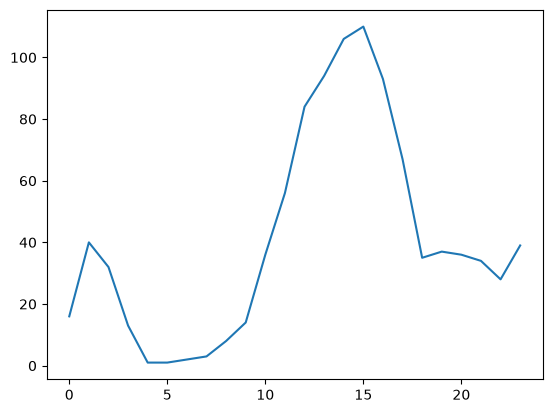

In [7]:
# Plot the hourly counts for our example day
plt.plot(df_day['cnt'])

If we pass x- and y-values, the line will take the path defined by the set of $(x_i, y_i)$.
```python
plt.plot(X_VALUES, Y_VALUES)
```

In our case coincidentally the hours of the day are noted as $0, \dots, 23$ so we se no actual change.

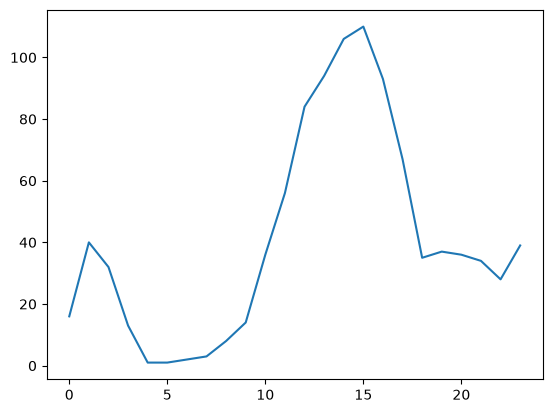

In [8]:
# Plot the hourly counts for our example day using explicit x values
plt.plot(df_day['hr'], df_day['cnt'])

By calling the `plot` function several times, we can plot multiple lines at once. We can use the `label` parameter to give each plot a name for each of the plots, which will then be displayed when `plt.legend` is called. With `plt.show()` we force the figure to be shown, then we can start a new plot.

With `plt.xlabel` and `plt.ylabel` we can add axis labels. With `plt.title` we can give the plot a title.

We can also customise a number of attributes such as `marker`, `linestyle` or `linewidth`. To create informative and beautiful plots, it is always worth having a look at the documentation.

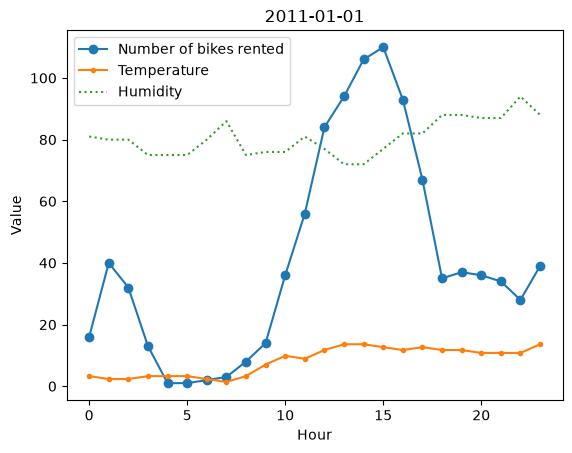

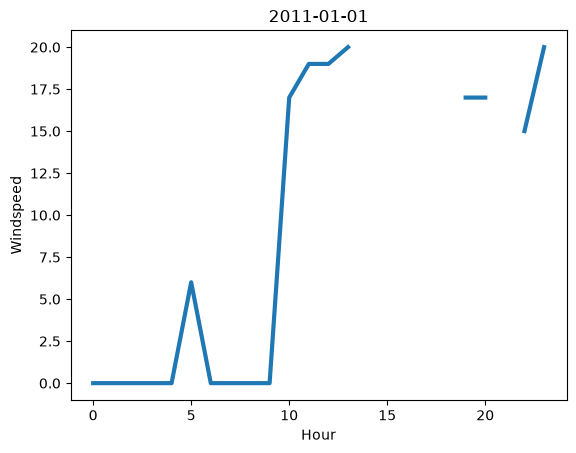

In [11]:
# Plot the hourly counts
plt.plot(df_day['hr'], df_day['cnt'], marker='o', label='Number of bikes rented')
# Plot the hourly temperature
plt.plot(df_day['hr'], df_day['temp'], marker='.', label='Temperature')
# Plot the hourly humidity
plt.plot(df_day['hr'], df_day['hum'], linestyle=':', label='Humidity')

# Specify labels, title and legend
plt.xlabel('Hour')
plt.ylabel('Value')
plt.title(day)
plt.legend()

# Show plot to be ready to start with a new figure
plt.show()

# Plot hourly windspeed
plt.plot(df_day['hr'], df_day['windspeed'], linestyle='-', linewidth=3)
plt.xlabel('Hour')
plt.ylabel('Windspeed')
plt.title(day)
plt.show()

With Matplotlib we can also build other types of graphs such as bar charts, histograms, boxplots, pie charts and many more. We'll come to that later today when visualizing real dataset.

## Pandas plotting functions

Pandas includes functionality to plot data right out of the dataframe, which should make the task of plotting even easier. Internally, Pandas makes use of Matplotlib. This is very nice, as we can build a basic plot and then still change things using Matplotlib functions afterwards. Pandas doesn't include every type of plot, however quite many are included. You can call them using the methods:

- line : line plot (default)
- bar : vertical bar plot
- barh : horizontal bar plot
- hist : histogram
- box : boxplot
- kde : Kernel Density Estimation plot
- density : same as ‘kde’
- area : area plot
- pie : pie plot
- scatter : scatter plot
- hexbin : hexbin plot.

All of these methods are available by using the dataframe's `plot` attribute. Let's take a closer look by creating scatter plots.

## Scatter plot
A scatterplot is a type of plot that uses Cartesian coordinates to display values for typically two variables for a data set.

Scatter plots can be drawn from Pandas dataframes using the `plot.scatter()` method. Scatter plots require numerical data for the x and y axes, which can now be specified using the column names. The axis labels are then automatically annotated. Using the `c` parameter, we can specify a third variable to be included in the plot by using different colours. We can then read the value of the point for this third variable from the colour bar. By specifying `alpha` we can set the opacity of the points, e.g. to make the overlapping of points more visible.

Can you spot the anomalous values?

<Axes: xlabel='temp', ylabel='atemp'>

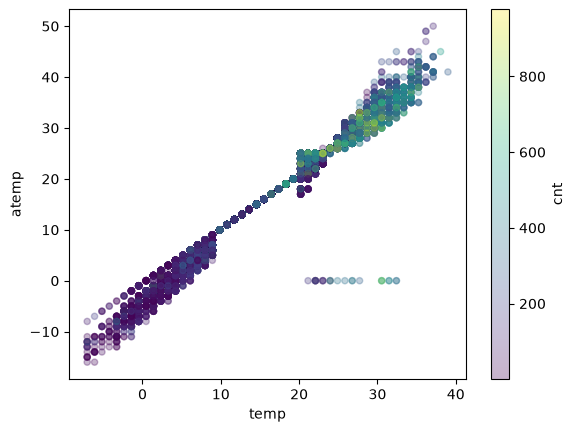

In [14]:
# Create a scatter with temp against atemp and colour by cnt
df.plot.scatter('temp', 'atemp', c='cnt', alpha=.3)

### Exercise 1a: Data loading
1. Load the dataframe to a variable `df_uci`. Use `index_col=0` as parameter to choose the `id` column as index. If you need a reminder of how to load the data, have a look at the last exercise!
2. Think about the following questions: Why was it quite intuitive to create a line plot for i.e. one day of our bike dataset. What might make it less useful for our UCI heart disease dataset?

In [16]:
# Load the dataframe
df_uci=pd.read_csv("./heart_disease_uci.csv", index_col=0)

### Exercise 1b: Scatter plots
1. Create a scatter plot with `age` on the x-axis and `thalch` on the y-axis.
2. Create a second plot with the same axes, but this time plotting the unique values of `num` in different colours.

    Notes:
   * You will need a for loop on the unique value `df_uci['num'].unique()`.
   * You will need to select the data for the specific `num` values as `df_uci[df_uci['num'] == num]`.
   * Use `plt.scatter` instead of the plot accessor of the dataframe to avoid creating a new plot for each call.
   * You can display a legend by calling `plt.legend()` if you have passed `label=num` to the `plt.scatter` function to specify the names.

<Axes: xlabel='age', ylabel='thalch'>

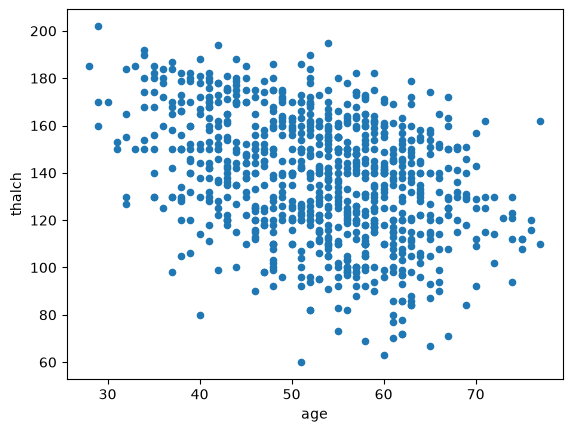

In [20]:
# Create a scatter plot with age and thalch
df_uci.plot.scatter("age", "thalch")

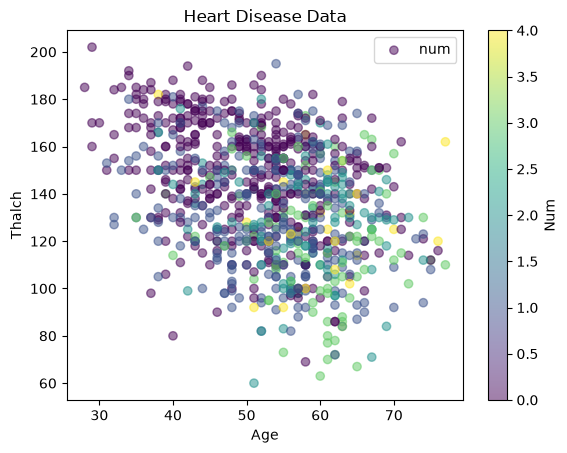

In [25]:
# Create a scatter plot with age and thalch and num in different colors
x = df_uci['age']
y = df_uci['thalch']
plt.scatter(x, y, c=df_uci['num'],  alpha=0.5, label='num')
# Legend and labels
plt.xlabel('Age')
plt.ylabel('Thalch')
plt.title('Heart Disease Data')
plt.colorbar(label='Num')
plt.legend()
plt.show()


## Pie plots

Important: Pie plots can sometimes be missleading as the human eye is not very good at interpreting angles. Nevertheless, pie plots are a common way of illustrating data outside of academia. So it is nice to know how to create pie plots, but use them carefully!

A pie chart is a circular statistical graphic, which is divided into slices to illustrate numerical proportion. You can create a pie plot with the dataframe's `plot.pie()` method. If your data includes any `NaN`, they will be automatically filled with 0. A ValueError will be raised if there are any negative values in your data.

As an example, let's compute the total number of hours per weather situation and the total number of bike rentals per weather situation.

In [26]:
# As an example, let's compute
# a) the total number of hours per weather situation (count)
# b) the total number of bike rentals per weather situation (sum)
weathersit_counts = df.groupby('weathersit')['cnt'].aggregate(['count', 'sum'])
weathersit_counts

,count,sum
weathersit,,
1,8653,1763998
2,3396,597060
3,1057,115905
4,3,223


Text(0.5, 1.0, 'Weathersit')

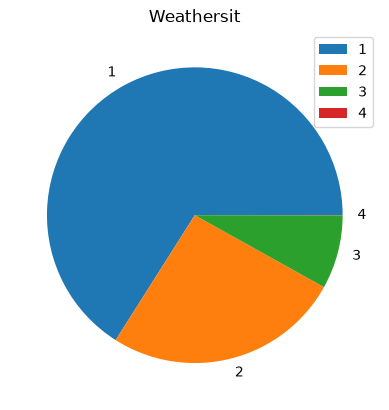

In [28]:
# Plot the the total number of hours per weather situation
weathersit_counts.plot.pie(y='count')
plt.title('Weathersit')

If you want to see the visualization of different columns in the same dataframe at the same time, use `subplots=True`. By passing `autopct='%.2f%%'` we specify that we want the values to be displayed in percent, using a floating point number with two decimal places followed by a percent sign (double `%%` because `autopct` uses a single percent sign as a special character, so the first one is used to escape the second).

Text(0.5, 1.0, 'Weathersit')

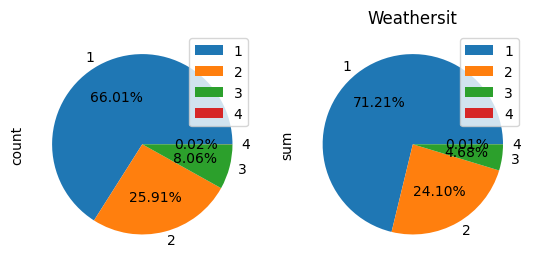

In [43]:
# Plot multiple pie plots using subplots=True
weathersit_counts.plot.pie(subplots=True, autopct='%.2f%%')
plt.title('Weathersit')

## Boxplots

A boxplot is a very common style of illustrating data. It is a (standardized) way of displaying the distribution of data based on five summary statistics
* minimum
* first quartile ($\operatorname{Q1}$)
* median ($\operatorname{Q2}$)
* third quartile ($\operatorname{Q3}$)
* maximum

It immediately shows outliers along with the values. It can also tell if the data is symmetrical, how tightly your data is grouped, and if and how your data is skewed.

The central part is the box spanned from $\operatorname{Q1}$ to $\operatorname{Q3}$ with the median line at its center. In front and after the box we have the so called "whiskers". For them there is no standard definition, but in matplotlib its definied using the interquartile range $\operatorname{IQR} = \operatorname{Q3} - \operatorname{Q1}$. The whiskers than are defined as $x_{\text{low}}$, the lowest values with $x_{\text{low}} \geq \operatorname{Q1} - 1.5\operatorname{IQR}$ for the lower whiskey and $x_{\text{up}}$  repectively as the highest data point with $x_{\text{up}} \leq \operatorname{Q3} + 1.5\operatorname{IQR}$ for the upper whisker.

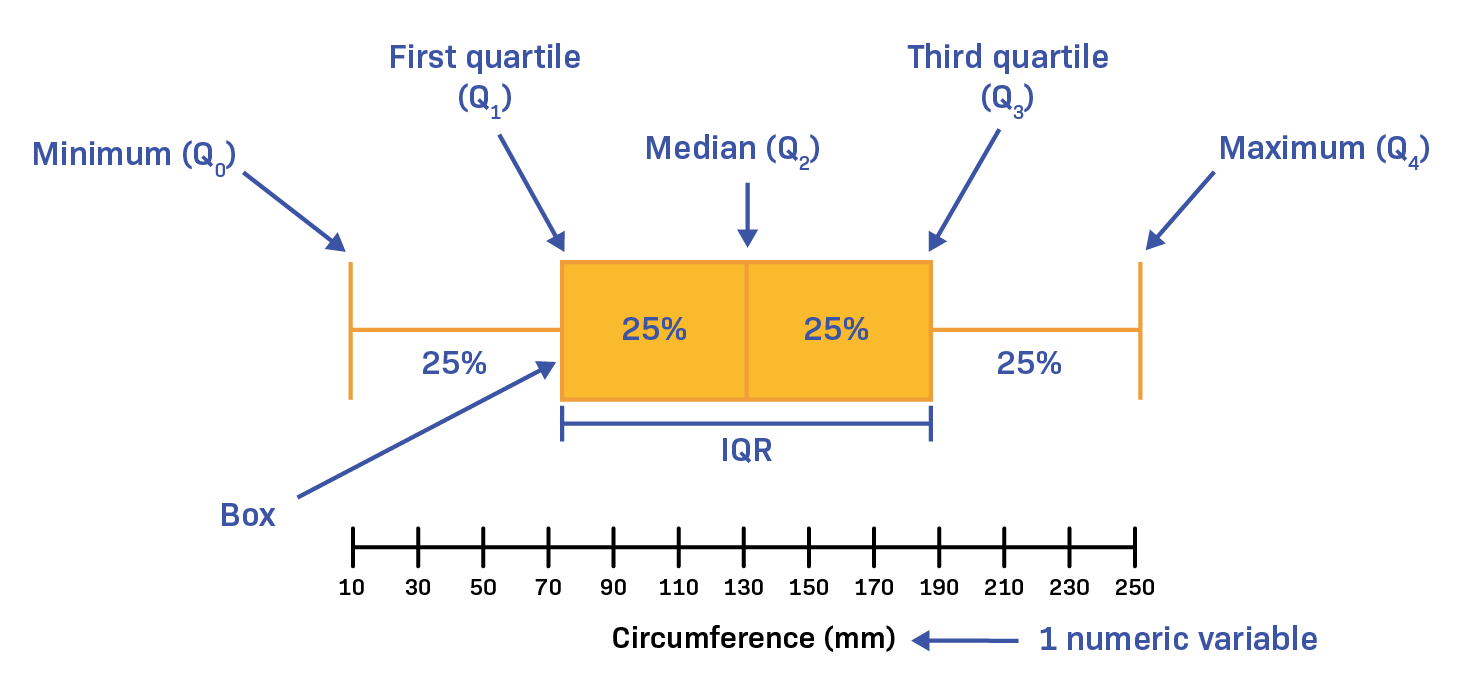

Let's create our first boxplot. By using `vert=False` we can make the plot being horizontal.

<Axes: >

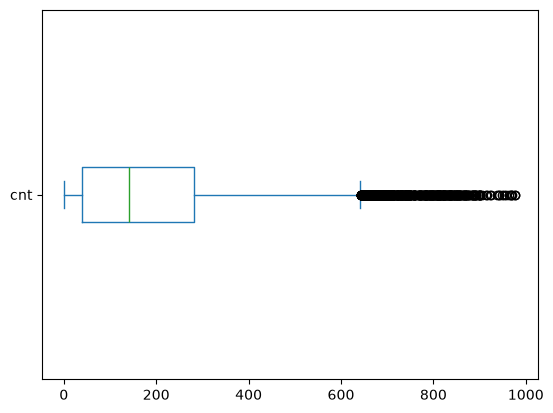

In [29]:
# Create a boxplot for the cnt column
df["cnt"].plot.box(vert=False)

We can also visualise boxplots for several variables at once. But because they are scaled differently, we cannot see them all properly.

<Axes: >

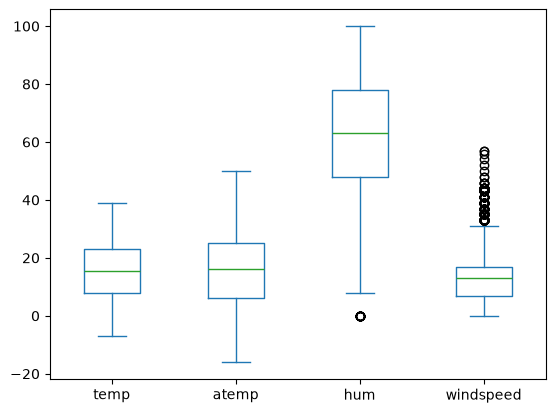

In [30]:
# Create a boxplot for all the columns of type float
df.select_dtypes('float').plot.box()

If we allow each boxplot to have it's own axis, different scaling is no longer an issue. To do this we can use the `subplots=True` parameter again. With `layout=(N, M)` we can specify that our figure has $N$ rows and $M$ columns.

temp            Axes(0.125,0.53;0.227941x0.35)
atemp        Axes(0.398529,0.53;0.227941x0.35)
hum          Axes(0.672059,0.53;0.227941x0.35)
windspeed       Axes(0.125,0.11;0.227941x0.35)
dtype: object

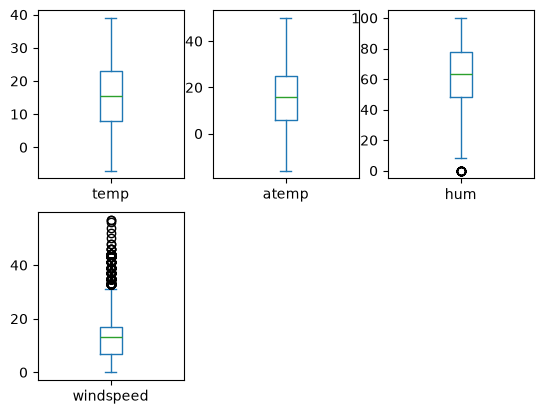

In [31]:
# Create a boxplot for all the columns of type float,
# allow subplots and specify a layout
df.select_dtypes('float').plot.box(subplots=True, layout=(2,3))

### Exercise 2a: Pie and barplot

1. Plot the ratio of patience by gender using a pie plot.
2. Plot the total number of records by gender using a bar plot.

Hint: you can use the `sex` column's `value_counts` method for computing the number of records by gender.

<Axes: >

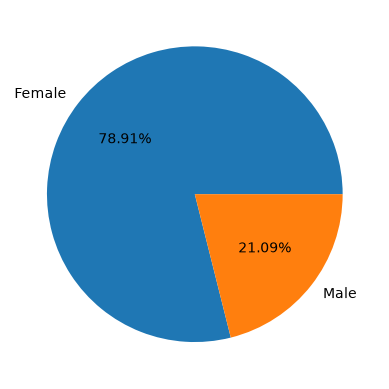

In [34]:
# Ratio of patience by gender using a pie plot.
df_uci["sex"].value_counts().plot.pie(autopct='%.2f%%', labels=['Female', 'Male'])

<Axes: xlabel='sex'>

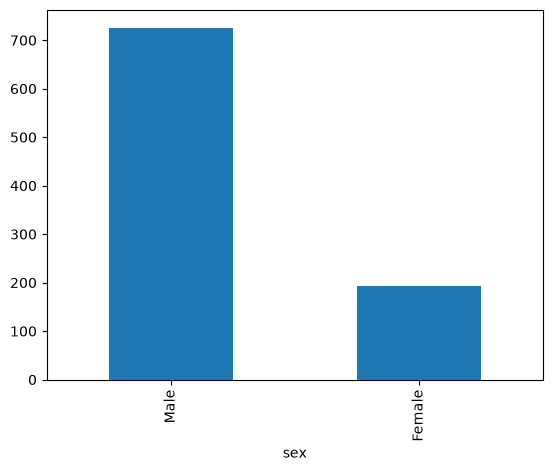

In [45]:
# Number of records by gender using a bar plot
df_uci["sex"].value_counts().plot.bar()

### Exercise 2b: Boxplots

1. Create boxplots for the columns of the UCI heart disease dataset.
2. Why might it be misleading to create boxplots for the `ca` or the `num` columns? What might be a more appropriate visualization of the distributions of these variables? Plot the better solution for `ca` and `num` (hint: you may need to use the `value_counts` method).

age            Axes(0.125,0.653529;0.133621x0.226471)
trestbps    Axes(0.285345,0.653529;0.133621x0.226471)
chol         Axes(0.44569,0.653529;0.133621x0.226471)
thalch      Axes(0.606034,0.653529;0.133621x0.226471)
oldpeak     Axes(0.766379,0.653529;0.133621x0.226471)
ca             Axes(0.125,0.381765;0.133621x0.226471)
num         Axes(0.285345,0.381765;0.133621x0.226471)
dtype: object

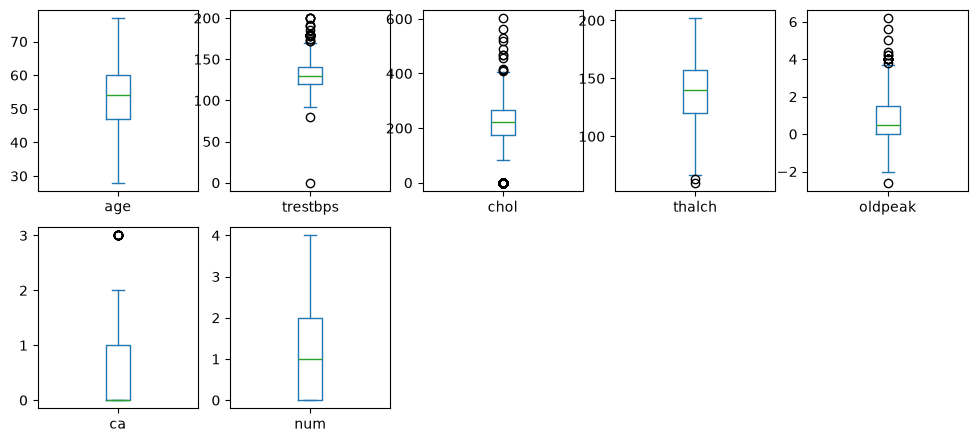

In [57]:
# Create boxplots
df_uci.plot.box(subplots=True, layout=(3,5), figsize=(12,8))

<Axes: xlabel='ca'>

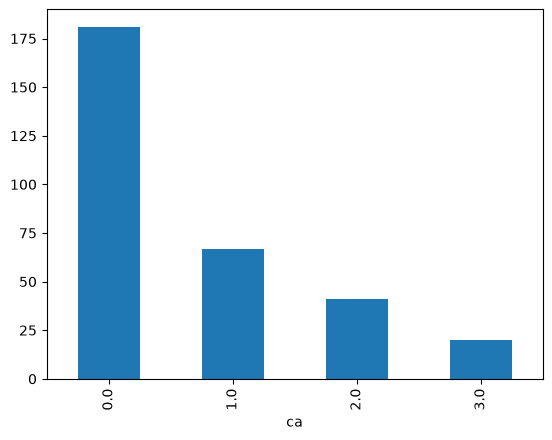

In [58]:
# Create a barplot of total frequencies of ca
df_uci["ca"].value_counts().plot.bar()

<Axes: xlabel='num'>

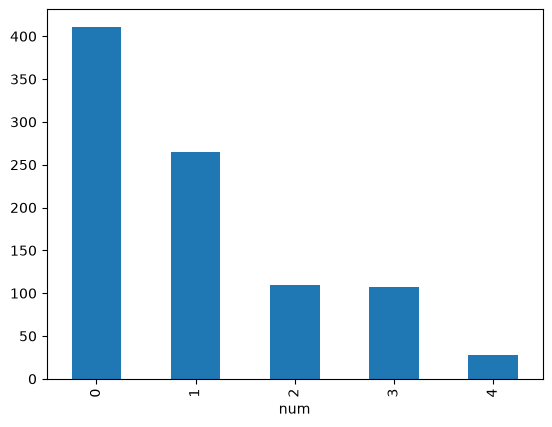

In [59]:
# Create a barplot of total frequencies of num
df_uci["num"].value_counts().plot.bar()

## Histograms and density plots
A histogram is a graphical display of data using bars of different heights. In a histogram, each bar groups numbers into ranges (called bins). Higher bars indicate that more data falls within that bin. A histogram shows the shape and spread of continuous sample data.

<Axes: ylabel='Frequency'>

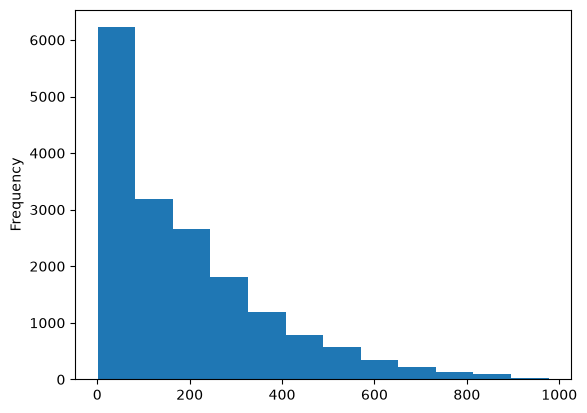

In [60]:
# Create histogram from cnt
df['cnt'].plot.hist(bins=12)

Kernel Density Estimator (KDE) plots are similar to histograms in that they also help us to visualise the distribution of a variable. One advantage of density plots over histograms is that they are better at determining the shape of the distribution because they aren't affected by the number of bins used, so we get a smooth curve. Another advantage is that we can more easily compare several variables in one figure.

<Axes: ylabel='Density'>

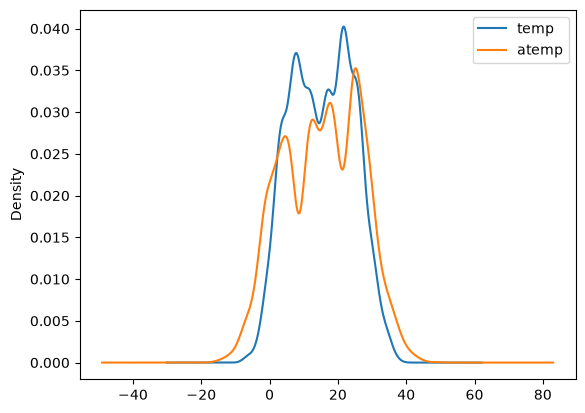

In [61]:
# Create kde plots from temp and atemp
df[['temp', 'atemp']].plot.kde()

### Exercise 3: Histogram und density plots

1. Why did we not choose the variable `cnt` for the kernel density estimator plot? Why can `cnt` be visualised nicely with a histogram, but might be misleading with a KDE plot? If you're not sure about your argument, make a KDE plot of `df['cnt']` and compare it with the histogram from above.

2. Plot histograms for the `trestbps` column for different numbers of bins (`bins=` argument, i.e. for 20, 50 and 100 bins).

    If you have a smaller number of bins, the overall distribution will look something like the bell curve of a normal distribution. The more bins you use to plot, the more you will see individual values appearing more frequently. Can you see which values occur more frequently than others? Continuous data, such as temperature, can theoretically take any value within a range. However, when measuring, sensors or humans often round to discrete values for reasons of precision or practicality.
    
3. Create a density plot for the `trestbps` column.

    What are the advantages and disadvantages of each plot? What can you see in some plots that you cannot see in others? variabl

<Axes: ylabel='Density'>

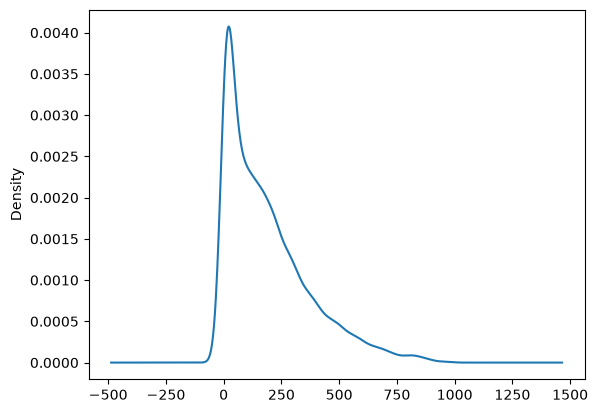

In [65]:
# Create a density plot for the cnt columns
df['cnt'].plot.kde()

<Axes: ylabel='Frequency'>

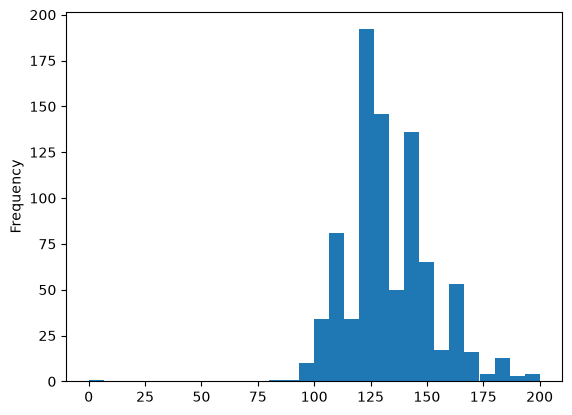

In [83]:
# Plot histograms for the trestbps column for different numbers of bins
df_uci["trestbps"].plot.hist(bins=30)

<Axes: ylabel='Density'>

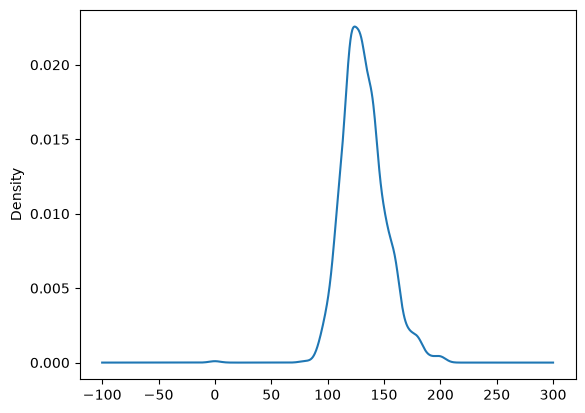

In [84]:
# Create a density plot for the trestbps
df_uci["trestbps"].plot.kde()

## Subplots

To better explain a relationship, it can be useful to combine several plots into one graph. The `plt.subplots` function in Matplotlib is used to create a figure and a set of subplots in a single call. It returns a tuple containing a figure and an array of axes objects, which you can use to plot data on each subplot.

For `nrows` (number of rows) and `ncols` (number of columns) the function be computed as follows:
```python
fig, axes = plt.subplots(nrows, ncols)
```

The axes array will be of shape $(n,m)$ for $n > 1$ and $m > 1$. For $n = 1$ or $m = 1$ it will be reduce to one dimensional array.

Shape of 'axes': (2,)


Text(0, 0.5, 'temp')

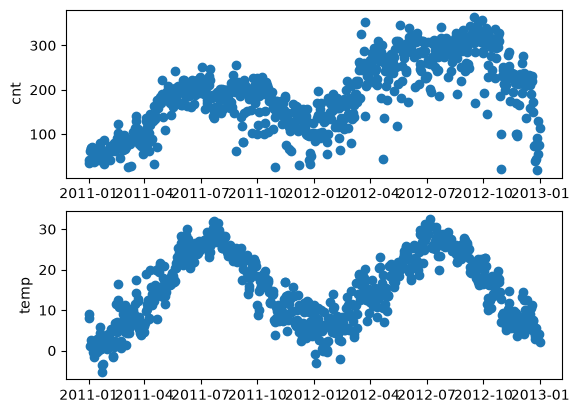

In [85]:
# create a plot with 2 rows and one column
fig, axes = plt.subplots(2, 1)
print("Shape of 'axes':", axes.shape)

# compute daily mean for cnt and temp
day = df.groupby('dteday')[['cnt', 'temp']].mean()

# plot in the first row
axes[0].scatter(day.index, day['cnt'])
axes[0].set_ylabel('cnt')

# second row
axes[1].scatter(day.index, day['temp'])
axes[1].set_ylabel('temp')

You can also use the Pandas `plot` accessor to draw subplots. For that you have to pass the specified axis from your `axes` array the `ax=axis` parameter, i.e. for the first subplot of the second row:
```python
df.plot.bar(ax=axes[1,0])
```

Shape of 'axes': (2, 3)


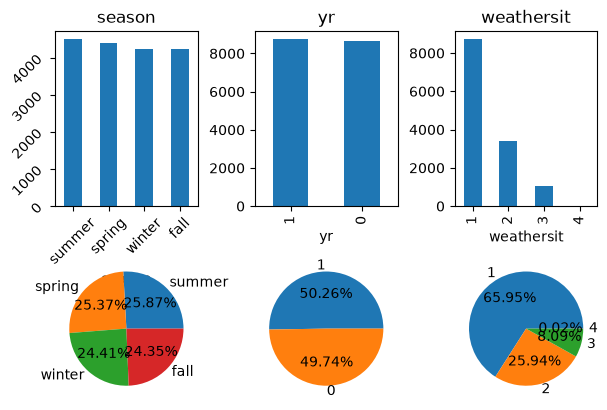

In [88]:
# create a plot with 2 rows and 3 columns
fig, axes = plt.subplots(2, 3, figsize=(7, 5))
print("Shape of 'axes':", axes.shape)

variables = ['season', 'yr', 'weathersit']

# loop over variable indices to create plots
for i in range(len(variables)):
    # compute the data
    data = df[variables[i]].value_counts()
    # set title
    axes[0,i].set_title(variables[i])
    # create plots
    data.plot.bar(ax=axes[0,i])
    data.plot.pie(ax=axes[1,i], autopct='%.2f%%', labels=data.index)
    # rotate x-ticks for season
    if i == 0:
        axes[0,0].tick_params(labelrotation=45)

# adjust space between plots
plt.subplots_adjust(wspace=.4)


### Exercise 4: Subplots

Group the `df_uci` by `dataset` and select the `chol` column. Create a subplot with two rows and use the Pandas `plot` accesor to plot

1. A Kernel density estimator plot (`kde`) in the first row
2. A histogram plot (`hist`) in the second row

Remember that with the Pandas `plot` accesor you have to pass the axis as `ax=axis` to the corresponding plotting methods.

For the KDE plot, the method call will throw an error: `LinAlgError`. This is due to the fact that for `Switzerland` the `chol` column has a no variation in the data (as we've seen above, it has a mean of 0 and standard deviation of 0). We therefore have to exclude the records for which the dataset is `Switzerland` (prior to grouping). You can do that by filtering as follows:
```python
df_uci[df_uci['dataset'] != 'Switzerland']
```

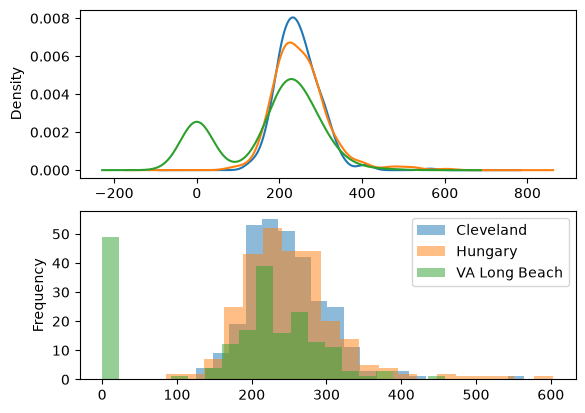

In [101]:
# Groupby dataset and select the chol column for datasets that are not Switzerland
df_sorted = df_uci[df_uci["dataset"] != "Switzerland"].groupby("dataset")["chol"]
# Create subplots
fig, axes =plt.subplots(2,1)


# Plot KDE and histogram
df_sorted.plot.kde(ax=axes[0])
df_sorted.plot.hist(ax=axes[1], bins=20, alpha=0.5)


# Add a legend
plt.legend()

## Seaborn

Most of the time we will be using `matplotlib` for plotting. But (as it is almost always the case in Python, there are a variety of libraries to choose from. Sometimes you may need a different library for a different type of plot. One example we will look at here is [seaborn's](https://seaborn.pydata.org). For some tasks it will make our work much easier, that's why this library is definitely worth a little chapter.

> Seaborn is a Python data visualization library based on matplotlib.
> It provides a high-level interface for drawing attractive and informative statistical graphics.

Seaborn by convention usually is imported as follows:
```python
import seaborn as sns
```

Note that if you do not use Google Colab but our own machine, you might have to install the packages first:
```
pip install seaborn
```

In [103]:
import seaborn as sns

### Seaborn pairplot
The `sns.pairplot` displays scatter plots for all combinations of numeric variables in the data frame. It is therefore an excellent starting point to get an overview. The variable names are aligned on the y and x axes to create a matrix with the corresponding scatter dependency plot. By default, histograms are plotted on the diagonal from the top left corner to the bottom right corner (where the x variable is equal to the y variable).

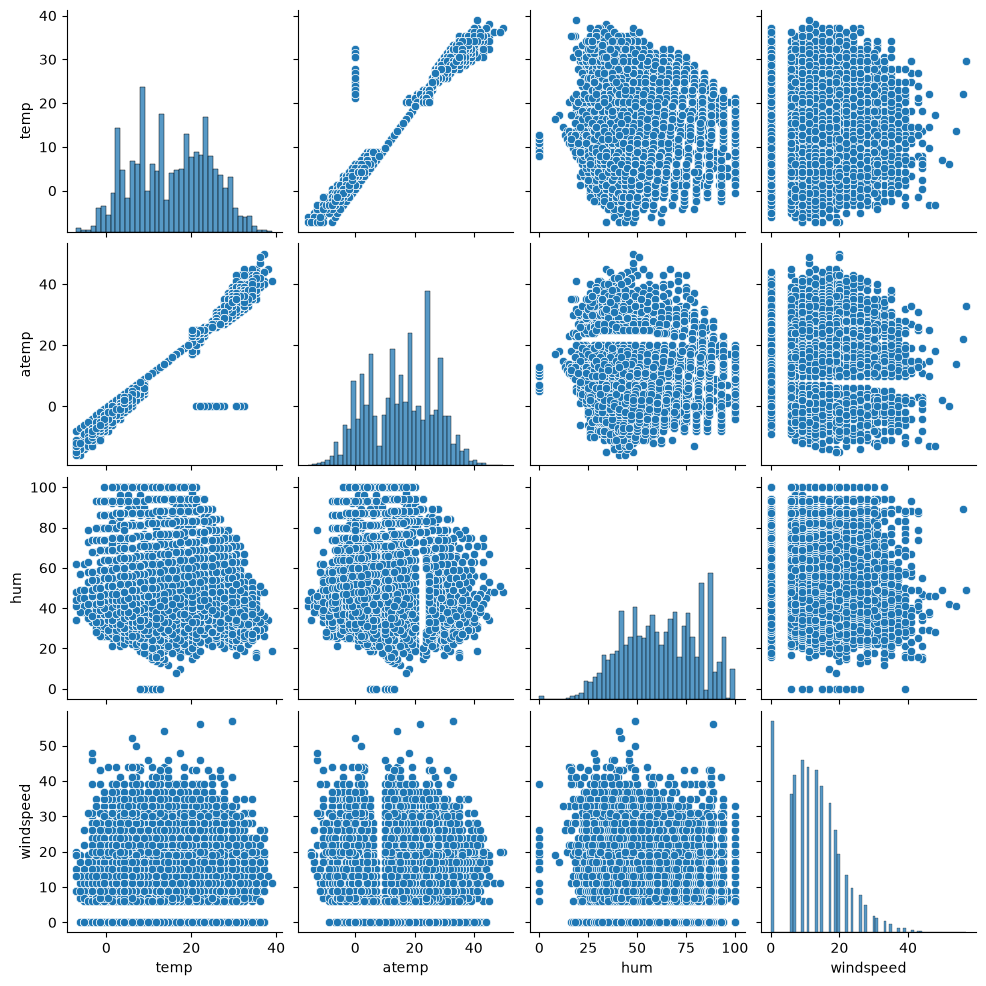

In [104]:
# Create a pairplot of columns of type float
sns.pairplot(df.select_dtypes('float'))

### Seaborn boxplot and violinplot

We already introduced boxplots in the previous exercise.  However, if you want to gain insight into the distribution of numerical variables depending on a categorical value, Seaborn boxplots can be very useful. By specifying `x` we can select a discrete  variable for the subplots, by specifying `y` we select the numerical variable.

<Axes: xlabel='hr', ylabel='cnt'>

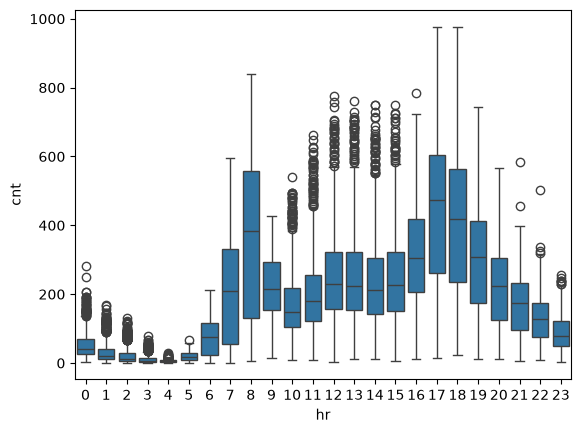

In [105]:
# Create boxplots of cnt by hour
sns.boxplot(df, x='hr', y='cnt')

Furthermore the Seaborn implementation offers a third dimension through the `hue` parameter.

As an example for that, let's first add a new variable `weekend` that indicates (derived from our timestamp) whether it is a weekend day or not.

In [106]:
# Add a new variable weekend
df['weekend'] = df['dteday'].dt.weekday >= 5

If we now differentiate between weekdays and weekends, it becomes unmistakably clear that these are two fundamentally different distributions.

<Axes: xlabel='hr', ylabel='cnt'>

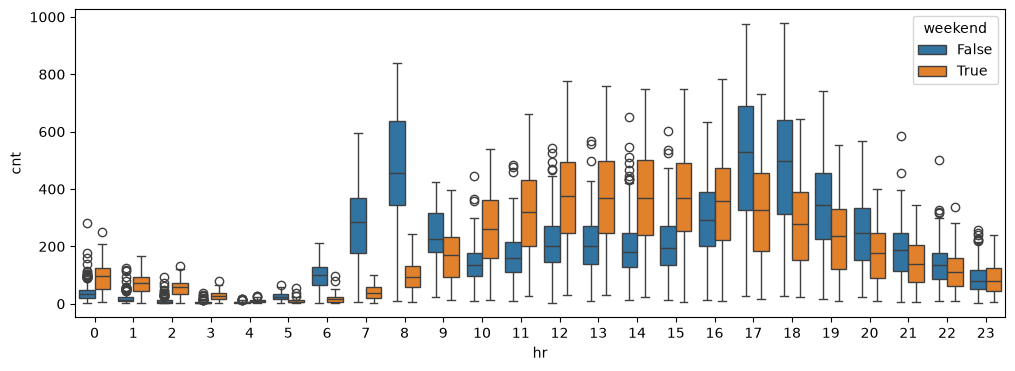

In [107]:
# Adjust the size of the figure
plt.figure(figsize=(12, 4))

# Create boxplots of cnt by hour with weekend True/False seperate
sns.boxplot(df, x='hr', y='cnt', hue='weekend')

**Violin plots** are a method of plotting numeric data and can be considered a combination of box plots and kernel density plots. They provide a more detailed view of the data distribution compared to box plots. On the other hand, box plots are better at showing outliers explicitly.

* Shape: The shape of the violin plot represents the density of the data at different values, similar to a kernel density plot.
* Median and Quartiles: Like box plots, violin plots can also show the median and quartiles of the data.

<Axes: xlabel='season', ylabel='cnt'>

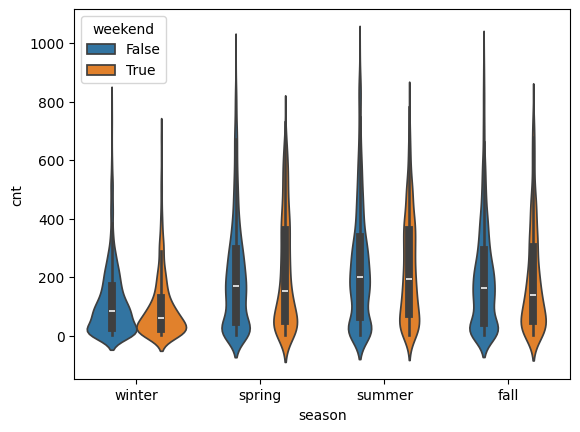

In [65]:
# Create boxplots of cnt by season with weekend True/False seperate
sns.violinplot(df, x='season', y='cnt', hue='weekend')

Especially when it comes to binary comparisons, using `split=True` makes it easy to compare the distributions.

<Axes: xlabel='season', ylabel='cnt'>

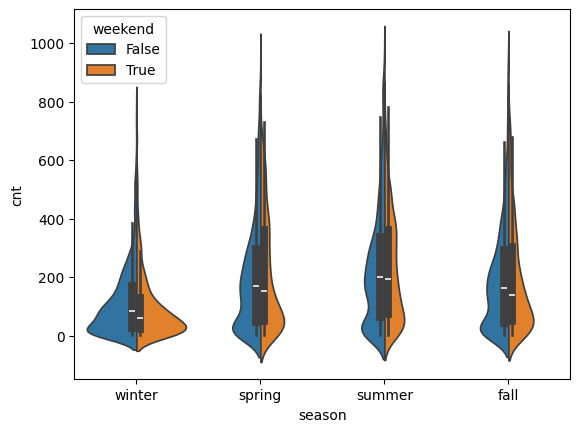

In [66]:
# Create boxplots of cnt by season with weekend True/False seperate using split=True
sns.violinplot(df, x='season', y='cnt', hue='weekend', split=True)

### Seaborn heatmaps

A heatmap is a powerful data visualization tool that represents data values in a matrix format, where individual values are depicted using colors. Heatmaps are particularly useful for identifying patterns, correlations, and trends in large datasets.

One famous use of heatmaps is in correlation plots. Here, the correlation between pairs of variables is computed using a correlation coefficient. Correlation plots provide significant exploratory value in data analysis by identifying relationships and improving understanding of the data. Furthermore, they are important for machine learning in terms of feature selection through the detection of multicollinearity (when two or more variables in a model are highly correlated), as this can lead to unstable and unreliable model estimates depending on the model architecture.

The so-called "correlation coefficient matrix" can be computed using the `corr` method of the dataframes. Before calling this method, we must exclude non-numerical variables.

By default the `corr` method uses the Pearson correlation coefficient $\rho_{x,y}$ , that measures the linear correlation between two variables. With standard deviation $\sigma$ and the sample covariance $\operatorname {cov} (x,y)$, it can be defined as:

$$\rho _{x,y}={\frac {\operatorname {cov} (x,y)}{\sigma _{x}\sigma _{y}}}.$$

The following applies: $-1 \le \rho_{x,y} \le 1$ with
* $\rho_{x,y} =  1$ for a perfect linear positive correlation
* $\rho_{x,y} = - 1$ for a perfect linear negative correlation and
* $\rho_{x,y} = 0$ for completely uncorrelated data

The Pearson correlation coefficient makes a few assumptions on the data. We will go into this again later in "Excursus: Level of measurement".

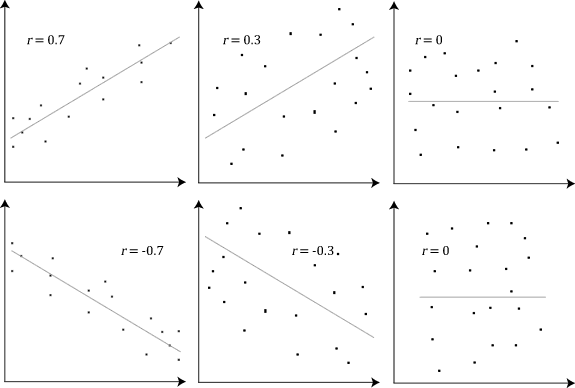

In [108]:
# Compute the correlation of dtypes 'number'
corr = df.select_dtypes('number').corr() # .drop(columns=['mnth', 'yr', 'hr', 'weathersit'])
corr

,yr,mnth,hr,holiday,weathersit,temp,atemp,hum,windspeed,cnt
yr,1.000000,-0.014752,-0.003867,0.006692,-0.019865,0.040913,0.039222,-0.083546,-0.010438,0.250075
mnth,-0.014752,1.000000,-0.001344,0.019239,0.012106,0.210715,0.217814,0.165908,-0.136825,0.125220
hr,-0.003867,-0.001344,1.000000,0.000479,-0.015472,0.137603,0.133750,-0.276498,0.138284,0.394697
holiday,0.006692,0.019239,0.000479,1.000000,-0.016789,-0.027340,-0.030973,-0.010588,0.001780,-0.031658
weathersit,-0.019865,0.012106,-0.015472,-0.016789,1.000000,-0.100212,-0.103259,0.424003,0.026241,-0.141106
temp,0.040913,0.210715,0.137603,-0.027340,-0.100212,1.000000,0.987672,-0.069881,-0.020640,0.404952
atemp,0.039222,0.217814,0.133750,-0.030973,-0.103259,0.987672,1.000000,-0.051918,-0.059915,0.401025
hum,-0.083546,0.165908,-0.276498,-0.010588,0.424003,-0.069881,-0.051918,1.000000,-0.288288,-0.323491
windspeed,-0.010438,-0.136825,0.138284,0.001780,0.026241,-0.020640,-0.059915,-0.288288,1.000000,0.097497
cnt,0.250075,0.125220,0.394697,-0.031658,-0.141106,0.404952,0.401025,-0.323491,0.097497,1.000000


Although heatmaps can be created directly with Matplotlib, we would like to present the variant with Seaborn here, since it is much easier, especially when working with dataframes.

The `sns.heatmap` function expects a dataframe of shape $(n,n)$ as first argument. Additional arguments can also be passed. For example the labels of the values with two decimal places can be added here with `annot=True, fmt='.2f'`.

<Axes: >

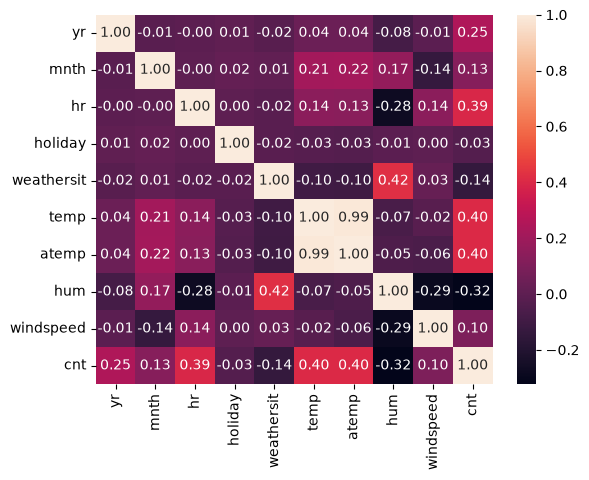

In [109]:
# Plot the correlation using a heatmap, add annotations with annot=True, fmt='.2f'
sns.heatmap(corr, annot=True, fmt='.2f')

### Exercise 5: Seaborn

1. Create a Seaborn pairplot of the UCI heart disease dataset using the following columns:
    ```python
   ['age', 'trestbps', 'chol', 'thalch', 'num']
    ```
    Use the arguments `hue='num'` and `corner=True`. What has changed?

2. Create a Seaborn boxplot. Use `num` as `x` param, `trestbps`  as `y` and `sex` ad `hue`.

    Compare the boxplot with the violin plot. What information can be seen in one plot that cannot be seen in the other?

3. Create a correlation plot for the UCI heart disease data. Note that you have to select the numerical columns before you can compute the correlation:
    ```python
    df_uci.select_dtypes('number').corr()
    ```

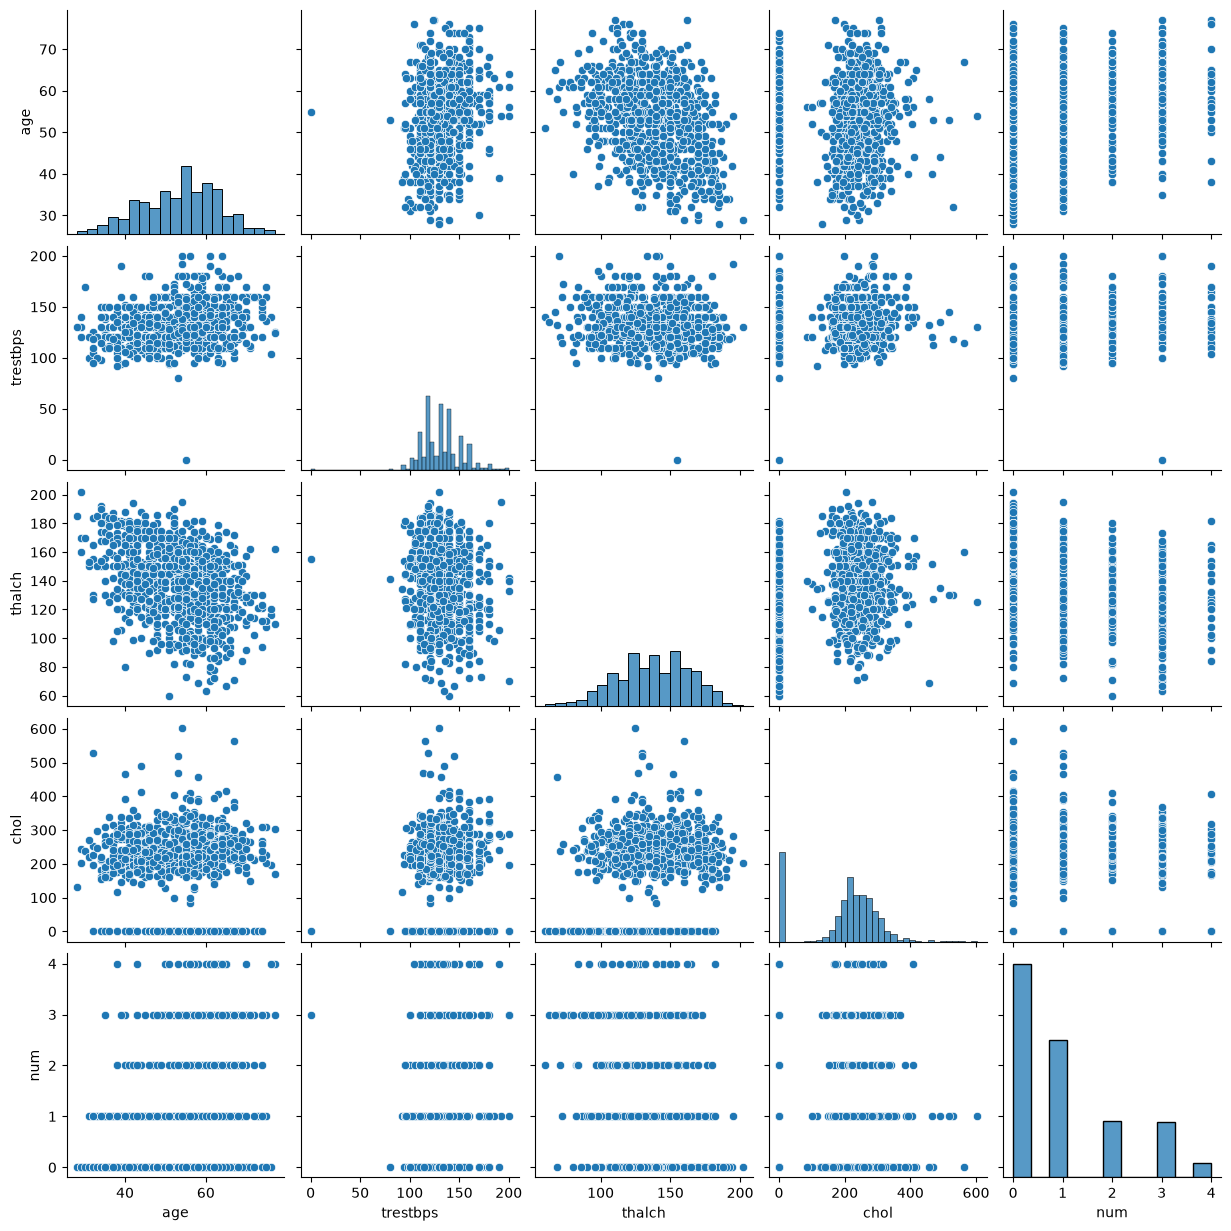

In [111]:
# 1. Create a Seaborn pairplot
sns.pairplot(df_uci[["age", "trestbps", "thalch", "chol", "num"]])

<Axes: xlabel='num', ylabel='trestbps'>

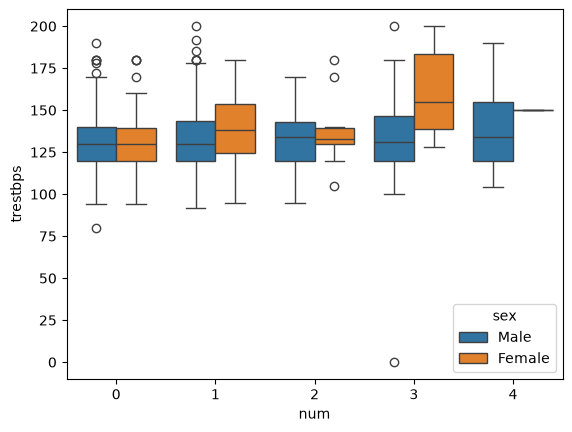

In [112]:
# 2. Create a Seaborn boxplot. Compare the boxplot with the violin plot.
sns.boxplot(df_uci, x='num', y='trestbps', hue ="sex")

<Axes: >

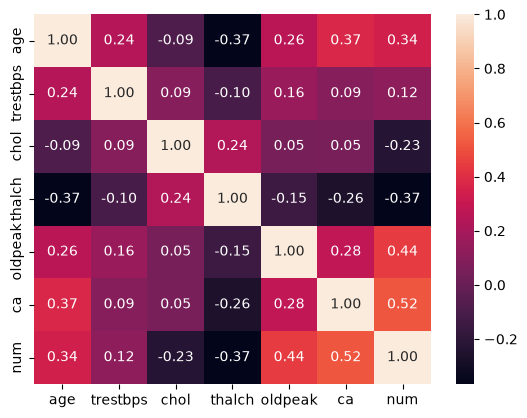

In [115]:
# 3. Create a correlation plot of the UCI heart disease data.
corr_uci = df_uci.select_dtypes('number').corr()
sns.heatmap(corr_uci, annot=True, fmt='.2f')